# 26 — ¿Está madura la predicción?

## Pregunta y alcance

Los cuadernos 15 a 25 construyeron y eligieron el modelo de pronóstico. Para elegir se compararon más de veinte
diseños, con varias reglas y varias definiciones de «sube». Las predicciones se ven bien, pero eso no dice si lo
son ni si se van a sostener. Este cuaderno lo pregunta de frente, con cinco pruebas fijadas antes de calcular:

1. **Una sola vara.** ¿Qué significa «sube», de una vez para todas las pruebas?
2. **La curva por adelanto.** ¿Hasta cuántos días antes sirve la predicción, y cuál es el adelanto real de uso?
3. **El sesgo de selección.** Después de elegir el mejor entre muchos diseños, ¿le sigue ganando al calendario?
4. **La honestidad del rango.** ¿El rango del 80 % contiene de verdad el 80 % de los días, y sus fallos llegan
   sueltos o en racha?
5. **La vigilancia.** ¿Cómo se detecta que el modelo dejó de funcionar, y qué predicciones guardadas esperan
   verificación?

Al final, una conclusión: para qué usos está madura la predicción y para cuáles no.

## Contenido

0. Qué se evalúa y con qué criterio.
1. Una sola vara de «sube».
2. La curva por adelanto.
3. Sesgo de selección: SPA y conjunto de confianza de modelos.
4. Honestidad del rango: Kupiec y Christoffersen.
5. Vigilancia: CUSUM y predicciones prospectivas.
6. El día dentro de un nivel estable.
7. Conclusión: ¿está madura la predicción?
8. Límites del análisis.

In [1]:
import sys, pathlib, warnings
RAIZ = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path[:0] = [str(RAIZ), str(RAIZ / "notebooks")]; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from matplotlib import pyplot as plt
from IPython.display import Markdown, display
import statsmodels.api   # se importa antes: al importarse reinstala su filtro de avisos
import pronostico as pr, madurez as mz

AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
TINTA, TINTA2, MUDO, SUP = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SUP, "axes.facecolor": SUP, "axes.spines.top": False,
    "axes.spines.right": False, "axes.edgecolor": MUDO, "axes.grid": True, "grid.color": "#e6e5e1",
    "grid.linewidth": .6, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "font.size": 10,
    "legend.frameon": False})
COLOR = {"M3s": AZUL, "M3": AZUL, "C0r": NARANJA, "control": MUDO}
NOMBRE = {"M3s": "M3s (elegido)", "C0r": "C0r (sin contexto)", "control": "control de calendario"}
MESES = ["", "ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
SAL = mz.CARPETA
fmt = dict(precision=1, thousands=".", decimal=",")
lee = lambda n, **k: pd.read_csv(SAL / n, **k)

if not (SAL / "spa_2026.csv").exists():
    raise SystemExit("Faltan las salidas: python notebooks/madurez.py --curva y después python notebooks/madurez.py")
y = mz.serie()
P = pd.read_parquet(SAL / "curva_filas.parquet")
print(f"Triage hasta el {mz.ULTIMO}. Filas de la curva por adelanto: {len(P):,} "
      f"(adelantos {sorted(int(a) for a in P.adelanto.unique())}, {P.origen.nunique()} domingos de origen).".replace(",", "."))

Triage hasta el 2026-09-20. Filas de la curva por adelanto: 7.434 (adelantos [1. 8. 15. 22]. 90 domingos de origen).


---
# 0. Qué se evalúa y con qué criterio

**Los modelos.** Se evalúan los tres que importan para decidir:
- **M3s**, el modelo elegido para la respuesta semanal: SARIMAX y LightGBM combinados, con los mecanismos externos
  medidos (Feria, noches festivas, fiestas lejanas, catástrofe, salud pública y red de aseguradores con compuerta),
  sin la fase fuerte de la COVID. En el rodante diario de 1 a 7 días se usa su versión con clima, **M3**;
- **C0r**, la misma combinación sin contexto externo: calendario, estación, nivel y memoria;
- **el control de calendario**: día de la semana, festivos y nivel de los últimos 28 días. Es la referencia que
  responde a «este efecto no lo explicaba ya el calendario».

En la prueba de sesgo de selección entran además todos los diseños guardados (26 en 2025 y 32 en 2026).

**Los usos.** «Madura» no tiene sentido sin decir para qué. Se distinguen cuatro usos:

| Uso | Pregunta | Adelanto |
|---|---|---|
| **A** | ¿Cómo será la semana siguiente, si los datos están al día? | 1 a 7 días |
| **B** | ¿Cómo será la semana, con el retraso real con que llegan los datos? | 15 a 21 días |
| **C** | Dentro de un periodo sin cambios de nivel, ¿qué días serán altos? | 1 y 15 días |
| **D** | ¿Cómo será un mes entero, visto con meses de antelación? | 60 a 273 días |

**El criterio**, fijado antes de calcular. Un uso está maduro si cumple las cuatro condiciones:
1. el adelanto es **útil**: en 2025 y en 2026 a la vez, el acierto en «sube» supera la tasa base y el puntaje de
   cuantiles es mejor que el del control;
2. el modelo elegido **le gana al control después de corregir por la selección** (SPA), o al menos no queda fuera
   del conjunto de los mejores (MCS). Solo se puede medir de 1 a 7 días, que es donde existen todos los diseños;
3. el **rango es honesto**: la proporción de días fuera del rango no se distingue del 20 % (Kupiec) y los fallos no
   llegan en racha (Christoffersen);
4. la **vigilancia** no da alarmas que no tengan explicación.

**Los años.** 2025 es el año con que se eligieron los modelos y 2026 el que se miró una sola vez. Ninguno es una
prueba limpia: los dos ya se usaron para decidir algo. Por eso se corrige por selección en la sección 3, y por eso
la única prueba sin ninguna mirada previa es la prospectiva de la sección 5.

---
# 1. Una sola vara de «sube»

**Qué se hizo.** Se fijó una única definición: un día **sube** si queda por encima de **V**, la media del mismo día
de la semana en las 8 semanas que terminan en el día en que se hace la predicción. Se exigen al menos 4 de esas 8
semanas con dato. La categoría es binaria, sin banda de «normal».

**Por qué.** Hasta ahora «sube» tuvo tres significados: por encima del control de calendario con nivel de 28 días
(cuadernos 15-23), por encima del control rápido (segunda vara, desde el 2 de octubre) y por encima de las 8 semanas
previas con una banda de ±5 % (cuadernos 24 y 25). Con varas distintas, un acierto del 69 % en una prueba y uno del
81 % en otra no se pueden comparar. V tiene tres ventajas:
- se conoce el día de la predicción, **sin ningún modelo**, y vale igual para cualquier adelanto y cualquier diseño;
- es lo que un jefe de urgencias entiende por «más de lo de costumbre»;
- convierte al control de calendario en un competidor más, en lugar de la regla con que se mide.

La banda del ±5 % se quitó porque se había elegido después de ver un reporte del hospital.

**Lo que hay que tener presente al leer los aciertos.** V no sabe que un lunes es festivo ni que el nivel acaba de
cambiar. Cualquier modelo que sepa de calendario o siga el nivel acierta más que V sin esfuerzo, de modo que **el
acierto absoluto frente a V exagera la habilidad del modelo**. La medida justa es la distancia entre el modelo y el
control, que también sabe de calendario y de nivel.

In [2]:
display(lee("vara.csv", index_col=0).style.format(**fmt)
        .set_caption("Proporción de días que «suben» con cada vara (rodante diario, adelantos 1-7)"))

,días (origen x adelanto),sube con el control de 28 días %,sube con el control rápido %,sube con V %,V y el control de 28 días discrepan %
año,,,,,
2025,2.534,"43,3","44,0","45,0","17,6"
2026,1.820,"48,0","47,6","53,1","18,8"


A partir de la tabla anterior se puede interpretar que **la vara cambiaba la respuesta en casi uno de cada cinco
días**: V y el control de 28 días clasifican distinto el 17,6 % de los días de 2025 y el 18,8 % de los de 2026. Las
cifras de acierto de los cuadernos anteriores no eran comparables entre sí, y a partir de aquí todas se miden con V.

En 2025 suben el 45,0 % de los días frente a V y en 2026 el 53,1 %. La diferencia es de nivel: V es una media de 8
semanas y se queda atrás cuando el volumen salta, como en el regreso de Nueva EPS en marzo y en el rebote de
septiembre. Con unos 55 % de días en la categoría más frecuente, **decir siempre lo mismo ya acierta alrededor del
55 %**, y esa es la tasa base contra la que se lee cualquier acierto.

---
# 2. La curva por adelanto

**Qué se hizo.** Se rehízo la respuesta semanal en cada domingo de 2025 y 2026 con cuatro adelantos: la semana
siguiente (días 1-7), la de después (8-14), la tercera (15-21) y la cuarta (22-28). Los adelantos 1 y 15 son los de
la validación con que se eligió M3s; el 8 y el 22 se corrieron para este cuaderno con el mismo diseño, reajustando
los modelos cada cuatro domingos. Para cada adelanto se midieron el error del día, el puntaje de cuantiles (que
premia a la vez acertar el centro y dar un rango justo), el acierto en «sube» frente a la tasa base y la cobertura
del rango del 80 %. Como referencias sin modelo se usaron V misma y el mismo día de la última semana conocida.

**Por qué.** Toda la validación hecha hasta ahora fue de 1 a 7 días. Pero la base la actualiza un tercero una vez
por semana: el 8 de octubre los datos llegaban al 20 de septiembre, y las dos predicciones semanales guardadas se
hicieron con 15 y 22 días de adelanto. **El adelanto de uso real es de 15 a 21 días**, y la calidad a 1 día no dice
nada de la calidad a 15.

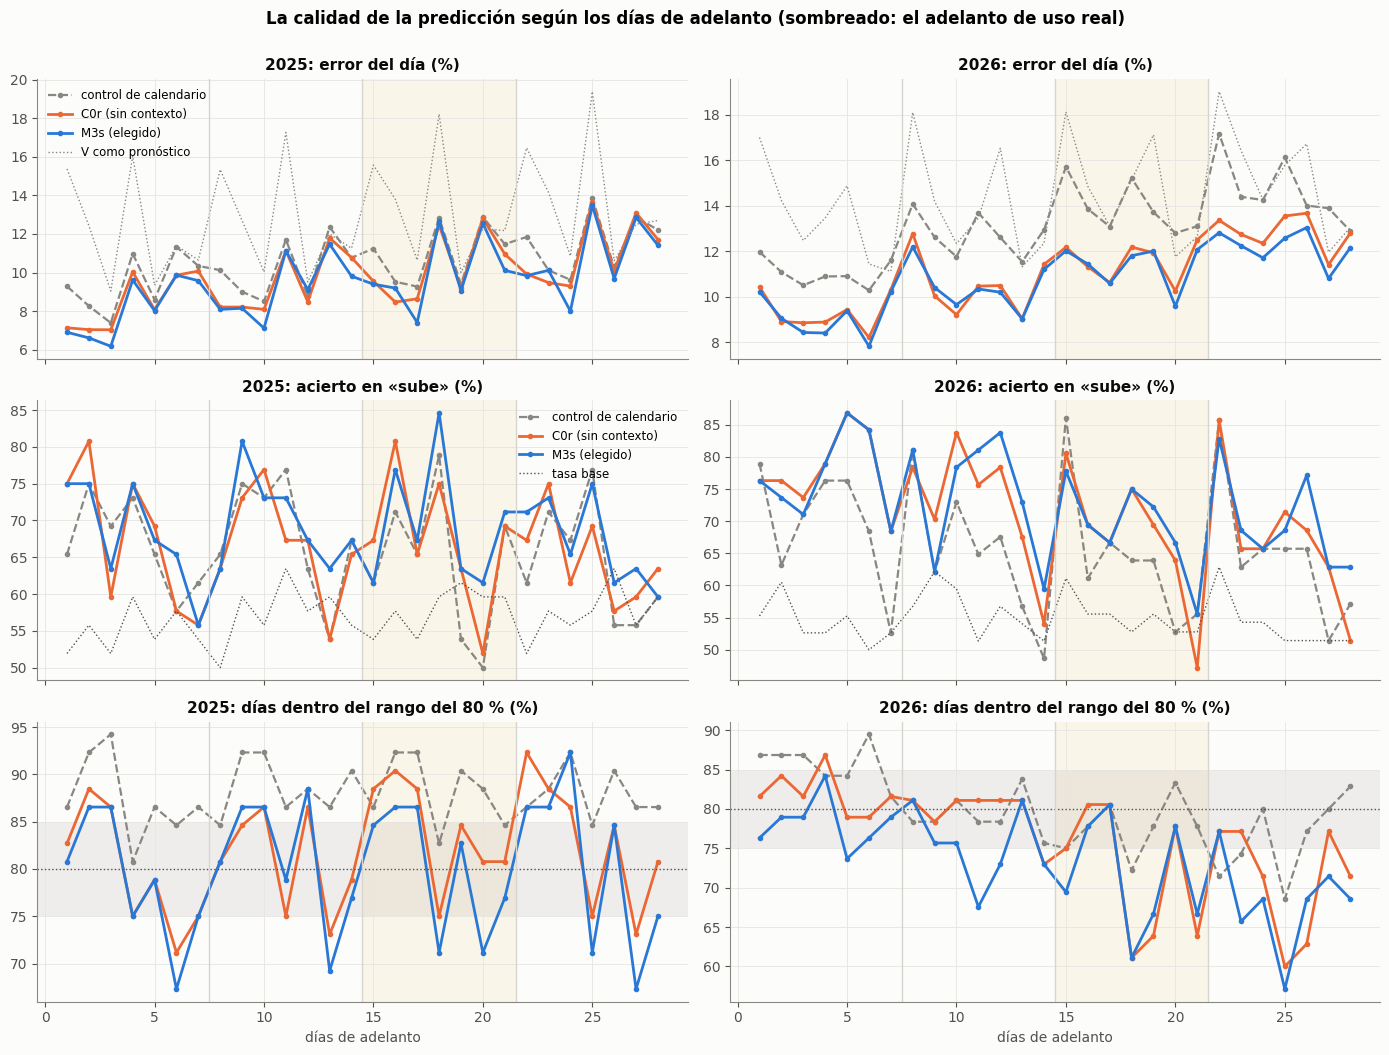

In [3]:
T = lee("curva.csv"); Bs = lee("curva_bases.csv")
fig, ax = plt.subplots(3, 2, figsize=(14, 10.5), sharex=True)
for j, a in enumerate((2025, 2026)):
    for m in ["control", "C0r", "M3s"]:
        t = T[(T.modelo == m) & (T.anio == a)].sort_values("h")
        kw = dict(color=COLOR[m], lw=2 if m != "control" else 1.6, ls="-" if m != "control" else "--",
                  marker="o", ms=3, label=NOMBRE[m])
        ax[0, j].plot(t.h, t["error del dia %"], **kw)
        ax[1, j].plot(t.h, t["acierto sube %"], **kw)
        ax[2, j].plot(t.h, t["cobertura 80 %"], **kw)
    b = Bs[Bs.anio == a].sort_values("h")
    ax[0, j].plot(b.h, b["error de V %"], color=MUDO, lw=1, ls=":", label="V como pronóstico")
    t = T[(T.modelo == "M3s") & (T.anio == a)].sort_values("h")
    ax[1, j].plot(t.h, t["tasa base %"], color=TINTA2, lw=1, ls=":", label="tasa base")
    ax[2, j].axhline(80, color=TINTA2, lw=1, ls=":")
    ax[2, j].axhspan(75, 85, color=MUDO, alpha=.12, lw=0)
    ax[0, j].set_title(f"{a}: error del día (%)"); ax[1, j].set_title(f"{a}: acierto en «sube» (%)")
    ax[2, j].set_title(f"{a}: días dentro del rango del 80 % (%)"); ax[2, j].set_xlabel("días de adelanto")
    for i in range(3):
        for x0 in (7.5, 14.5, 21.5): ax[i, j].axvline(x0, color="#d6d5d0", lw=1)
        ax[i, j].axvspan(14.5, 21.5, color=AMARILLO, alpha=.07, lw=0)
ax[0, 0].legend(fontsize=8.5); ax[1, 0].legend(fontsize=8.5)
fig.suptitle("La calidad de la predicción según los días de adelanto (sombreado: el adelanto de uso real)",
             fontweight="bold", y=1.0)
plt.tight_layout(); plt.show()

In [4]:
bloque = lambda h: f"{(h - 1) // 7 * 7 + 1}-{(h - 1) // 7 * 7 + 7}"
TB = T.assign(dias=T.h.map(bloque)).groupby(["dias", "modelo", "anio"], sort=False)[
    ["puntaje cuantiles %", "error del dia %", "acierto sube %", "tasa base %", "BSS sube %", "cobertura 80 %"]].mean()
TB = TB.unstack("anio").reorder_levels([1, 0], axis=1).sort_index(axis=1, level=0, sort_remaining=False)
display(TB.style.format(**fmt).set_caption("La curva por bloques de una semana (media de los 7 adelantos de cada bloque)"))
U = lee("utiles.csv")
U["días"] = U.h.map(bloque)
display(U.groupby(["modelo", "días"], sort=False)["útil"].agg(["sum", "count"])
        .rename(columns={"sum": "adelantos útiles", "count": "de"})
        .style.set_caption("Adelantos útiles por la regla (supera la tasa base y al control, en 2025 y en 2026)"))

A partir de la figura y las tablas anteriores se puede interpretar que **la predicción se degrada despacio y le
sigue ganando al control hasta cuatro semanas antes**:
- **El error del día de M3s crece alrededor de un punto por semana de adelanto:** 8,1 % en 2025 y 9,1 % en 2026 para
  la semana siguiente; 10,1 % y 11,4 % en la tercera, que es el adelanto de uso real; 10,8 % y 12,2 % en la cuarta. El
  control va siempre por encima (de 9,5 % a 11,5 % en 2025 y de 11,0 % a 14,7 % en 2026), y V como pronóstico, más
  arriba aún (de 12,0 % a 15,3 %).
- **El acierto en «sube» supera la tasa base en todos los bloques**, de 67 % a 77 % frente a 54-58 %. La distancia
  que cuenta es la que lo separa del control: en 2025, de 1,3 a 5,2 puntos según el bloque; en 2026, de 4,7 a 9,2
  puntos. De nuevo, el año con escalones de la red es el que separa al modelo del calendario.
- **Por la regla, M3s es útil en 24 de los 28 adelantos:** los 7 de la semana siguiente, 6 de la segunda, los 7 de la
  tercera y 4 de la cuarta. C0r lo es en 21. A partir del día 26 la ventaja deja de ser constante.
- **Lo que se rompe con el adelanto es el rango, no el centro.** En 2025 la cobertura del 80 % se mantiene entre 78,6 %
  y 81,0 % en los cuatro bloques. En 2026 baja de 78,2 % en la semana siguiente a 75,3 %, 71,4 % y 68,2 %. El modelo
  anuncia a tres semanas un rango tan estrecho como a una, y en un año de choques eso no alcanza.

La lectura de fondo es que **el adelanto de uso real, de 15 a 21 días, es útil para el número esperado**: el error
sube del 8-9 % al 10-11 %, y el modelo sigue entre 0,8 y 2,5 puntos de error por delante del control.

### Los adelantos lejanos: meses vistos desde diciembre

Los cuadernos 24 y 25 ya predijeron meses enteros desde el 31 de diciembre: septiembre de 2023 a 2026, y marzo,
julio y agosto de 2026. Aquí se miden con la misma vara (V con las 8 semanas que terminan el 31 de diciembre) y las
mismas métricas, sin recalcular nada. En septiembre de 2026, los días del 21 al 27 vienen de un reporte del hospital
y solo se usan para comparar.

In [5]:
L = lee("lejanos.csv", index_col=[0, 1])
display(L.style.format(**fmt).format("{:.0f}", subset=["dias"])
        .set_caption("Meses predichos desde diciembre, con la vara única"))

A partir de la tabla anterior se descubrió que **vista desde diciembre, la predicción de un mes no es mejor que la
del calendario**:
- en septiembre de 2025 y de 2026 M3s tiene menos error que la regresión anual de calendario (6,1 % frente a 7,0 % y
  5,6 % frente a 12,1 %); en septiembre de 2023 y de 2024 empata con ella (9,6 % frente a 9,0 % y 18,1 % frente a
  17,6 %);
- en los tres meses difíciles de 2026 gana uno (marzo, 13,1 % frente a 22,1 %) y pierde dos (julio, 11,9 % frente a
  7,2 %; agosto, 20,0 % frente a 12,5 %);
- con la vara única, la tasa base de un solo mes es muy alta (del 52 % al 97 %), porque V es el nivel de noviembre y
  diciembre, y el mes predicho suele quedar todo por encima o todo por debajo. El acierto en «sube» de M3s la supera
  en septiembre de 2025, julio y agosto de 2026; la iguala en septiembre de 2026 y queda por debajo en los demás;
- el rango del mes es irregular: cubre el 90-100 % de los días en tres septiembres y el 43 % en 2024. No es
  demasiado estrecho ni demasiado ancho de forma sistemática: depende de si el año cambió de nivel.

**A meses de distancia, lo que decide el error es si la red de salud cambia de nivel en el camino**, y eso no está en
ninguna variable que se conozca en diciembre.

---
# 3. Sesgo de selección: SPA y conjunto de confianza de modelos

**Qué se hizo.** Se reunieron todas las predicciones guardadas con origen rodante diario y adelantos de 1 a 7 días:
26 diseños en 2025 y 32 en 2026, contando las combinaciones tal como se definieron en su día. Se dejaron fuera los
que predicen una parte del total (bandas de edad, Nueva EPS y el resto) y los dos que solo tienen 19 y 37 orígenes.
Para cada origen se promedió la pérdida de los 7 adelantos, con tres pérdidas: el puntaje de cuantiles (la
principal), el Brier de «sube» con V y el error de la mediana. Sobre esas series se aplicaron dos pruebas:
- **SPA de Hansen (2005)**, la prueba de habilidad predictiva superior. Pregunta si **el mejor de todos** los
  diseños le gana al comparador de verdad, o si su ventaja es la que se espera de haber escogido el máximo entre
  muchos intentos. Se usó contra el control y contra C0r, y también solo con M3;
- **conjunto de confianza de modelos** (MCS, Hansen, Lunde y Nason, 2011). Descarta uno a uno los diseños que son
  peores que algún otro con significancia, hasta quedarse con los que no se pueden separar del mejor con un 90 % de
  confianza.

Las dos usan un bootstrap estacionario por bloques de 14 orígenes (5.000 repeticiones), porque las pérdidas de días
seguidos están correlacionadas. Están en la librería `arch`.

**Por qué.** Esta es la prueba directa de la duda «¿está bien o solo parece?». Cuando se prueban veinte diseños y se
queda el mejor, su ventaja sobre el control está inflada: alguno tenía que salir primero aunque todos fueran
iguales. El SPA da la probabilidad de ver una ventaja así de grande si ninguno fuera mejor que el control.

In [6]:
S = pd.concat([lee("spa_2025.csv"), lee("spa_2026.csv")])
display(S.set_index(["año", "pérdida", "comparador"]).style.format(**fmt)
        .format("{:.3f}", subset=["p SPA, todos", "p SPA, solo M3"])
        .set_caption("SPA: ¿le gana el mejor diseño, o M3, al comparador? (p < 0,05 = sí, después de corregir)"))

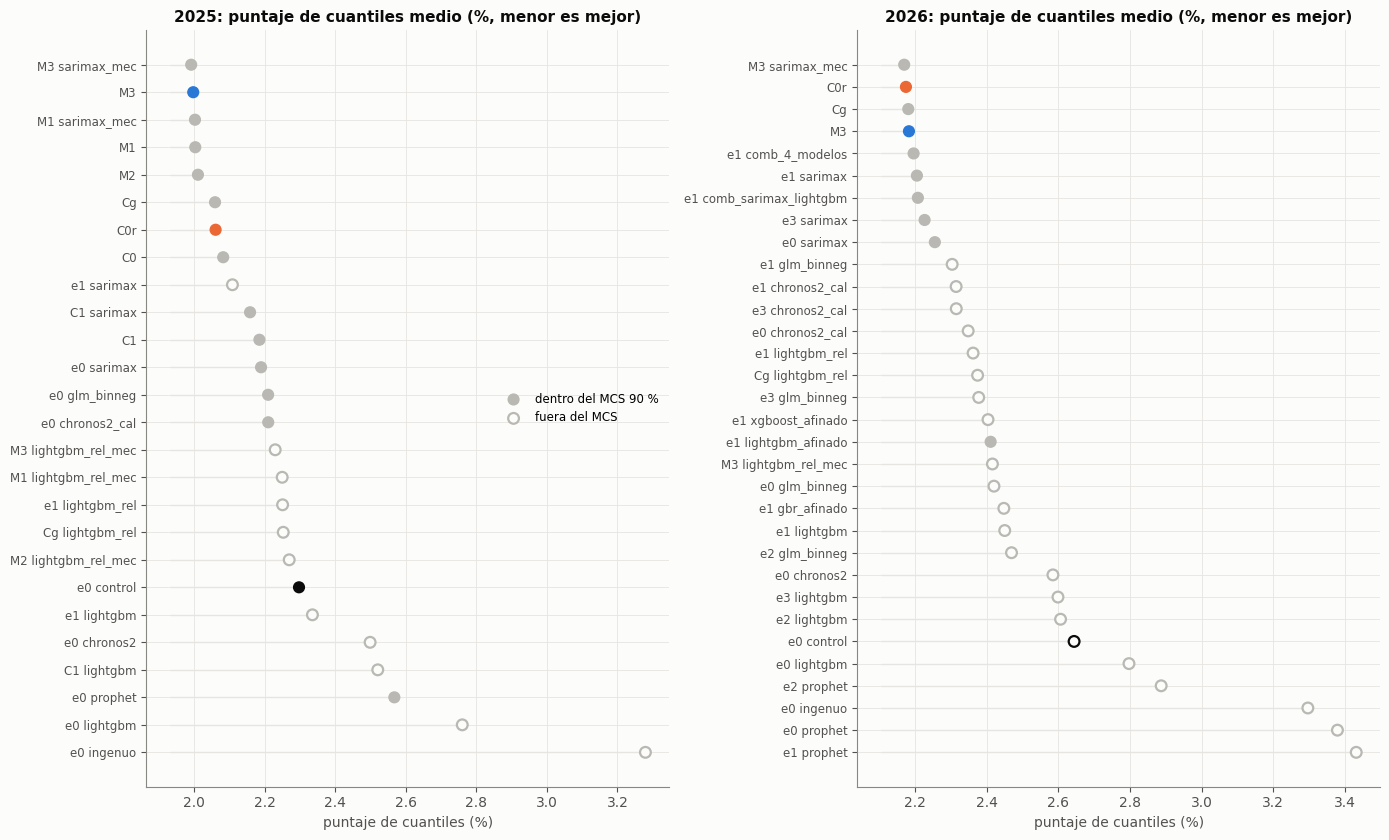

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 8.5))
for j, a in enumerate((2025, 2026)):
    M = lee(f"mcs_{a}_pin.csv", index_col=0).sort_values("pérdida media", ascending=False)
    yy = np.arange(len(M)); v = 100 * M["pérdida media"].values
    col = [{"M3": AZUL, "C0r": NARANJA, "e0 control": TINTA}.get(n, "#b9b8b3") for n in M.index]
    dentro = M["en el conjunto"].values
    ax[j].hlines(yy, v.min() * .97, v, color="#e6e5e1", lw=1)
    ax[j].scatter(v[dentro], yy[dentro], s=60, c=np.array(col)[dentro], zorder=3, label="dentro del MCS 90 %")
    ax[j].scatter(v[~dentro], yy[~dentro], s=60, facecolors=SUP, edgecolors=np.array(col)[~dentro], lw=1.6, zorder=3,
                  label="fuera del MCS")
    ax[j].set_yticks(yy); ax[j].set_yticklabels(M.index, fontsize=8.5)
    ax[j].set_title(f"{a}: puntaje de cuantiles medio (%, menor es mejor)"); ax[j].set_xlabel("puntaje de cuantiles (%)")
ax[0].legend(fontsize=8.5, loc="center right")
plt.tight_layout(); plt.show()

In [8]:
filas = []
for a in (2025, 2026):
    for perd, nom in mz.PERDIDAS.items():
        M = lee(f"mcs_{a}_{perd}.csv", index_col=0)
        filas.append({"año": a, "pérdida": nom, "diseños en el conjunto": int(M["en el conjunto"].sum()), "de": len(M),
                      "M3 dentro": "sí" if M.loc["M3", "en el conjunto"] else "no",
                      "C0r dentro": "sí" if M.loc["C0r", "en el conjunto"] else "no",
                      "control dentro": "sí" if M.loc["e0 control", "en el conjunto"] else "no",
                      "mejor": M.index[0]})
display(pd.DataFrame(filas).set_index(["año", "pérdida"]).style.set_caption("El conjunto de confianza de modelos (90 %)"))

A partir de las tablas y la figura anteriores se descubrió que **la ventaja sobre el calendario es firme en 2026 y
dudosa en 2025**:
- **En 2025**, el mejor de los 26 diseños mejora al control un 13,3 % en puntaje de cuantiles. Pero el SPA da
  p = 0,124: entre 25 aspirantes, una ventaja así puede salir solo por haber escogido el máximo. Con M3 solo, sin
  corregir por los demás, el puntaje da p = 0,083, el Brier de «sube» 0,028 y el error de la mediana 0,052. El
  conjunto de confianza retiene 15 de los 26 diseños **y el control está entre ellos**: en 2025, hasta noviembre un
  año sin escalones, el control no se puede separar del mejor.
- **En 2026**, la ventaja sobre el control es clara: el mejor diseño mejora un 18,0 %, con SPA p = 0,027 en puntaje y
  0,022 en error, y M3 solo da p < 0,001 en las tres pérdidas. El conjunto de confianza retiene 10 de 32 diseños y
  deja fuera al control.
- **Frente a C0r no hay ninguna diferencia demostrable.** Corregido por la selección, el SPA da p = 0,60 en 2025 y
  de 0,84 a 0,99 en 2026. En 2026, M3 queda un 0,4 % por detrás de C0r en puntaje. Probado solo, sin corregir, M3
  le gana a C0r en 2025 (p = 0,034 en puntaje), pero eso es justo lo que la corrección enseña a no creer, porque M3
  se eligió con 2025.

La lectura conjunta coincide con lo medido el 2 de octubre: **lo que el modelo sabe hacer mejor que el calendario es
seguir los cambios de nivel de la red de salud**, y 2026 es el año que los tiene. Sobre el total diario de 1 a 7
días, la aportación de los mecanismos externos (la diferencia entre M3 y C0r) es menor de lo que esta prueba alcanza
a separar. Eso no dice que los mecanismos no actúen: el cuaderno de mecanismos midió que la noche festiva se aprende
y que quitar la fase fuerte de la COVID ayuda. Dice que, sumados al volumen total de un año, sus días son pocos para
mover la pérdida media de forma demostrable.

---
# 4. Honestidad del rango: Kupiec y Christoffersen

**Qué se hizo.** Un rango del 80 % es honesto si deja fuera el 20 % de los días, ni más ni menos, y si esos días
fuera llegan sueltos. Se aplicaron tres pruebas clásicas de la evaluación de intervalos:
- **Kupiec (1995):** ¿la proporción de días fuera del rango se distingue del 20 %?
- **Christoffersen (1998), independencia:** ¿quedar fuera hoy hace más probable quedar fuera mañana?
- **Christoffersen, cobertura condicional:** las dos cosas a la vez.

Se aplicaron al rodante diario a 1 día, a la respuesta semanal por adelanto (con los días en orden de fecha) y al mes
a ciegas. La media de la semana se probó aparte, solo con Kupiec, porque hay una por semana. Además se midió, para
cada cuantil, qué proporción de días cae por debajo de él.

**Por qué.** El cuaderno 24 encontró que el rango semanal a ocho meses cubría el 56 % de las semanas, y la
validación de M3s, que en 2026 cubría alrededor del 60 %. Un rango demasiado estrecho es un modelo que promete más
seguridad de la que tiene. La prueba de independencia mira justo el mecanismo sospechoso: cuando el error es de
nivel (la red cambió y el modelo no lo sabe), se repite todos los días de la semana y los fallos llegan en racha.

In [9]:
K = lee("cobertura.csv")
K = K[K.modelo.isin(["M3", "M3s", "C0r", "control"])]
display(K.set_index(["serie", "modelo", "año"]).style.format(**fmt)
        .format("{:.3f}", subset=["p Kupiec", "p independencia", "p cobertura condicional"])
        .format("{:.0f}", subset=["n"])
        .set_caption("Rango del 80 % por día (p < 0,05 = el rango no es honesto en ese sentido)"))
display(lee("cobertura_semana.csv").set_index(["modelo", "días", "año"]).style.format(**fmt)
        .format("{:.3f}", subset=["p Kupiec"]).format("{:.2f}", subset=["rho (2025)"])
        .set_caption("Rango del 80 % de la media de la semana"))

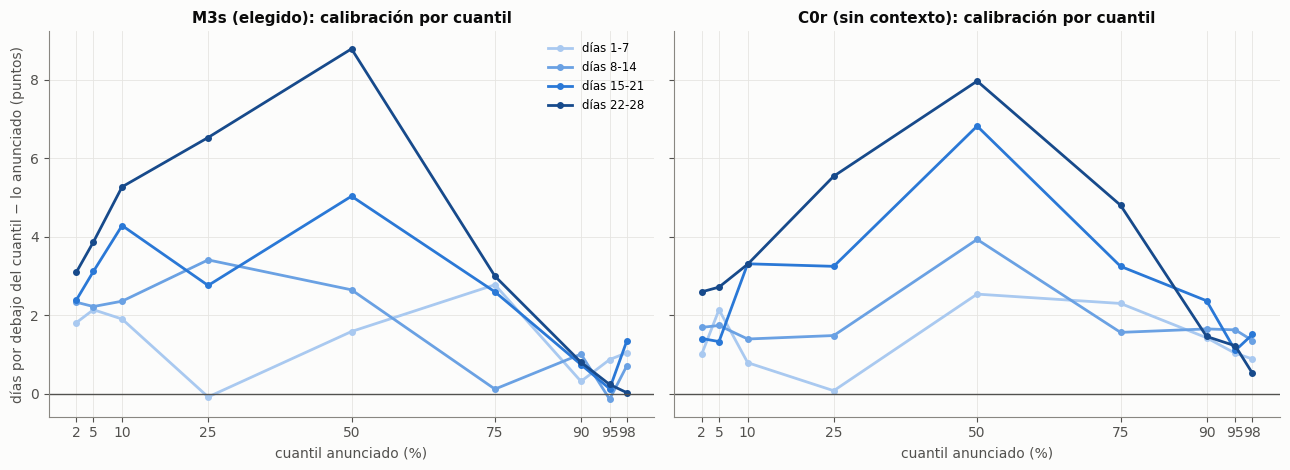

In [10]:
Pt = lee("pit.csv"); nominal = 100 * pr.QL
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
tonos = {"1-7": "#a9c9f0", "8-14": "#6aa1e3", "15-21": AZUL, "22-28": "#174a8b"}
for j, m in enumerate(["M3s", "C0r"]):
    for _, r in Pt[Pt.modelo == m].iterrows():
        ax[j].plot(nominal, r[pr.QCOL].values.astype(float) - nominal, marker="o", ms=4, lw=2,
                   color=tonos[r["días"]], label=f"días {r['días']}")
    ax[j].axhline(0, color=TINTA2, lw=1); ax[j].set_title(f"{NOMBRE[m]}: calibración por cuantil")
    ax[j].set_xlabel("cuantil anunciado (%)"); ax[j].set_xticks(nominal)
ax[0].set_ylabel("días por debajo del cuantil − lo anunciado (puntos)"); ax[0].legend(fontsize=8.5)
plt.tight_layout(); plt.show()

A partir de las tablas y la figura anteriores se descubrió que **el rango es honesto a un día y deja de serlo con el
adelanto, por fallos que llegan en racha**:
- **Rodante diario a 1 día:** los rangos de M3 y C0r son honestos en los dos años. M3 deja fuera el 20,8 % de los
  días en 2025 y el 19,5 % en 2026, y la cobertura condicional da p = 0,574 y 0,972.
- **Semana siguiente (días 1-7):** el rango del día de M3s es honesto (p = 0,177 y 0,550). Pero el de la media de la
  semana cubre el 81 % de las semanas en 2025 y solo el 61 % en 2026 (p de Kupiec = 0,006).
- **Desde la segunda semana**, la independencia falla en todos los bloques y en los dos años. Después de un día fuera
  del rango, la probabilidad de que el siguiente también quede fuera es del 33 % al 51 %, frente al 14-23 % después
  de un día dentro. **El error es de nivel: cuando el modelo no sabe que la red cambió, se equivoca toda la semana en
  la misma dirección.**
- En 2026 se suma un problema de proporción: a 15-21 días queda fuera el 28,6 % de los días (p = 0,001) y el 42 % de
  las semanas.
- **En la calibración por cuantil, la cola de abajo pesa más de lo anunciado.** Entre el 12 % y el 15 % de los días
  caen por debajo del cuantil 10, y del 52 % al 59 % por debajo de la mediana, más cuanto mayor es el adelanto. Las
  sorpresas son sobre todo caídas (Nueva EPS, el terremoto) y el modelo las subestima.

El control también falla la independencia en todos los bloques. **El defecto no es de M3s: es de cualquier modelo
que no conozca el estado de la red con semanas de anticipación.**

---
# 5. Vigilancia: CUSUM y predicciones prospectivas

**Qué se hizo.** Si el modelo está bien calibrado, cada día real cae en una posición al azar dentro de su
distribución anunciada; convertida a la escala normal, esa posición (z) tiene media 0 y desviación 1. Se aplicó un
**CUSUM tabular de dos lados** (Page, 1954) sobre z, en orden de fecha: acumula las desviaciones que pasan de medio
punto y da una alarma cuando la suma supera 5. Una alarma «arriba» significa que lo real viene quedando por encima de
lo anunciado; «abajo», lo contrario. Tras cada alarma la suma vuelve a cero, de modo que un desajuste que persiste
da alarmas repetidas. Cada alarma se cruzó con la cronología de choques conocidos.

**Por qué.** La pregunta «¿seguirá prediciendo así de bien?» no se contesta mirando el pasado una vez: se contesta
vigilando. El CUSUM es la herramienta estándar de control de calidad para detectar que un proceso se salió de su
comportamiento, y aquí detecta cuándo el modelo empieza a fallar en una dirección.

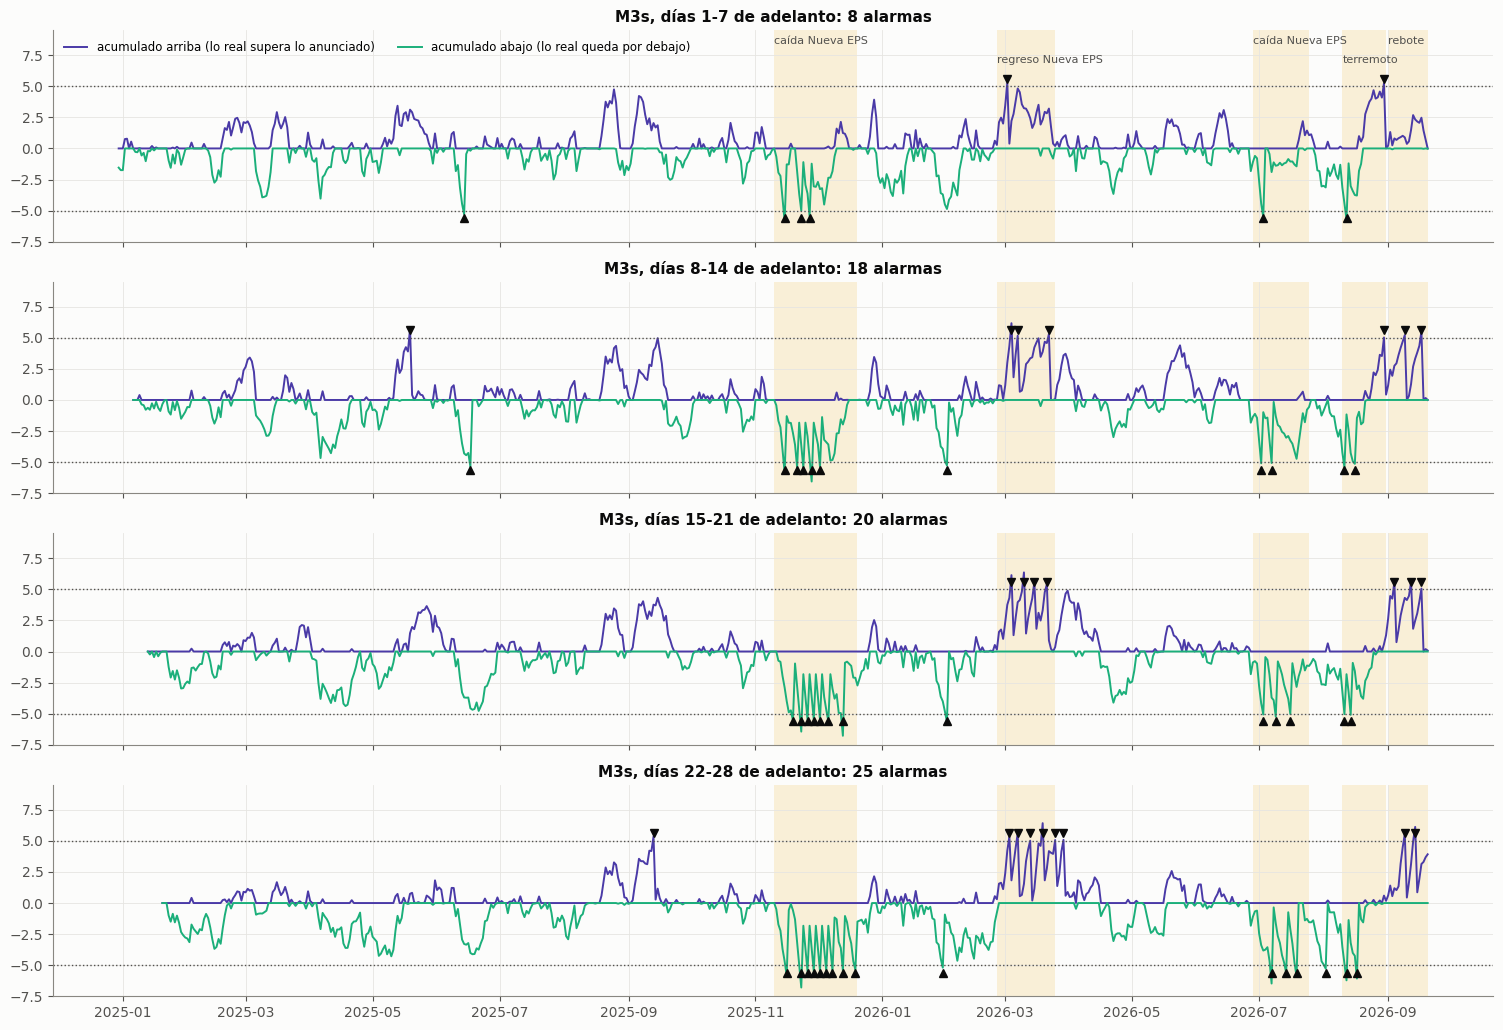

In [11]:
CHOQUES = [("2025-11-10", "2025-12-20", "caída de Nueva EPS"), ("2026-02-25", "2026-03-25", "regreso de Nueva EPS"),
           ("2026-06-28", "2026-07-25", "nueva caída de Nueva EPS"), ("2026-08-10", "2026-08-31", "terremoto"),
           ("2026-09-01", "2026-09-20", "rebote tras el terremoto")]
al, Sv = mz.vigilancia(P)
fig, ax = plt.subplots(len(Sv), 1, figsize=(15, 2.6 * len(Sv)), sharex=True)
for i, (lead, g) in enumerate(Sv.items()):
    for a, b, n in CHOQUES:
        ax[i].axvspan(pd.Timestamp(a), pd.Timestamp(b), color=AMARILLO, alpha=.14, lw=0)
    ax[i].plot(g.fecha, g.c_arriba, color=VIOLETA, lw=1.4, label="acumulado arriba (lo real supera lo anunciado)")
    ax[i].plot(g.fecha, -g.c_abajo, color=AQUA, lw=1.4, label="acumulado abajo (lo real queda por debajo)")
    for s in (5, -5): ax[i].axhline(s, color=TINTA2, lw=1, ls=":")
    a_ = al[al["días"] == f"{lead}-{lead + 6}"]
    for _, r in a_.iterrows():
        ax[i].plot(pd.Timestamp(r.fecha), 5.6 if r.lado == "arriba" else -5.6, "v" if r.lado == "arriba" else "^",
                   color=TINTA, ms=6)
    ax[i].set_title(f"M3s, días {lead}-{lead + 6} de adelanto: {len(a_)} alarmas"); ax[i].set_ylim(-7.5, 9.5)
ax[0].legend(fontsize=8.5, ncol=2, loc="upper left")
CORTO = {"caída de Nueva EPS": "caída Nueva EPS", "regreso de Nueva EPS": "regreso Nueva EPS",
         "nueva caída de Nueva EPS": "caída Nueva EPS", "terremoto": "terremoto", "rebote tras el terremoto": "rebote"}
for k, (a, b, n) in enumerate(CHOQUES):
    ax[0].text(pd.Timestamp(a), 8.4 if k % 2 == 0 else 6.9, CORTO[n], fontsize=8, color=TINTA2)
plt.tight_layout(); plt.show()

In [12]:
def explicada(f):
    f = pd.Timestamp(f)
    for a, b, n in reversed(CHOQUES):                    # si dos ventanas se solapan, cuenta el choque mas reciente
        if pd.Timestamp(a) <= f <= pd.Timestamp(b) + pd.Timedelta(days=21): return n
    return "sin choque conocido"
al["choque"] = al.fecha.map(explicada)
display(al.groupby(["días", "choque"], sort=False).agg(alarmas=("fecha", "size"), primera=("fecha", "min"),
                                                       última=("fecha", "max"))
        .style.set_caption("Alarmas del CUSUM y el choque con que coinciden (hasta 3 semanas después)"))

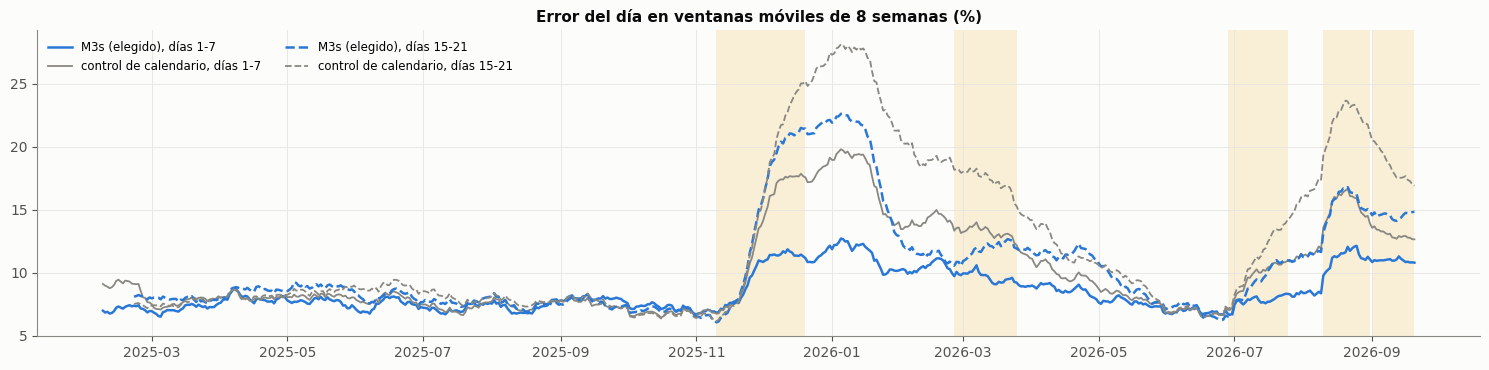

In [13]:
fig, ax = plt.subplots(1, 1, figsize=(15, 3.8))
for lead, ls in [(1, "-"), (15, "--")]:
    for m in ["M3s", "control"]:
        g = P[(P.modelo == m) & (P.adelanto == lead)].groupby("fecha").ape.mean().rolling(56, min_periods=40).mean()
        ax.plot(g.index, 100 * g.values, color=COLOR[m], lw=1.8 if m == "M3s" else 1.3, ls=ls,
                label=f"{NOMBRE[m]}, días {lead}-{lead + 6}")
for a, b, n in CHOQUES: ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color=AMARILLO, alpha=.14, lw=0)
ax.set_title("Error del día en ventanas móviles de 8 semanas (%)"); ax.legend(fontsize=8.5, ncol=2)
plt.tight_layout(); plt.show()

**Las predicciones prospectivas.** Son las únicas que no tienen ninguna mirada previa: se guardaron con fecha y
versión del código antes de que existiera el dato, y no se rehacen. La tabla dice cuántos de sus días tienen ya un
conteo real, sea de la base o de un reporte del hospital escrito a mano (que solo sirve para comparar).

In [14]:
display(lee("prospectivas.csv").set_index("predicción").style.set_caption("Predicciones guardadas antes de conocer lo real"))

,datos hasta,días,adelanto,guardada,días con dato real,de
predicción,,,,,,
semana_2026-10-05_C0r,2026-09-20,2026-10-05 a 2026-10-11,15-21,2026-10-06,0,7
semana_2026-10-05_M3s,2026-09-20,2026-10-05 a 2026-10-11,15-21,2026-10-06,0,7
semana_2026-10-12_M3s,2026-09-20,2026-10-12 a 2026-10-18,22-28,2026-10-06,0,7
2026-09-14_origen_2026-08-31_C0r,2026-08-31,2026-09-14 a 2026-09-20,14-20,2026-10-06,7,7
2026-09-14_origen_2026-08-31_M3s,2026-08-31,2026-09-14 a 2026-09-20,14-20,2026-10-06,7,7
2026-10_desde_2026-09-20,2026-09-20,2026-10-01 a 2026-10-31,11-41,2026-10-07,0,31
"mes a ciegas, septiembre de 2026",2025-12-31,2026-09-01 a 2026-09-30,244-273,2026-10-07,27,30


A partir de la figura y las tablas anteriores se descubrió que **la vigilancia detecta cada choque conocido y casi
nada más**:
- de las 71 alarmas de los cuatro adelantos, **64 coinciden con un choque conocido**: la caída de Nueva EPS de
  noviembre de 2025, su regreso en marzo de 2026, la nueva caída de julio, el terremoto del 10 de agosto y el rebote
  de septiembre;
- **un choque persistente da alarmas repetidas**, hasta 9 por episodio: después de cada reinicio, la suma se vuelve
  a llenar porque el desajuste sigue ahí. Cuanto mayor es el adelanto, más alarmas da cada choque, porque el modelo
  tarda más en enterarse;
- **quedan 7 alarmas sin choque conocido.** Cuatro caen entre enero y octubre de 2025, un periodo sin escalones de la
  red (el 19 de mayo, el 14 y el 17 de junio, y el 13 de septiembre). Eso fija la tasa de falsas alarmas: **alrededor
  de una por adelanto cada diez meses**, mayor que la nominal porque los errores de días seguidos están
  correlacionados. Las otras tres caen entre el 30 de enero y el 1 de febrero de 2026, en tres adelantos a la vez, y
  apuntan a una semana baja real que los datos disponibles no explican;
- el error en ventanas móviles muestra lo mismo de otra forma: el de M3s sube en cada choque y vuelve a su nivel en
  unas semanas.

**Las predicciones prospectivas no tienen todavía con qué verificarse.** La semana del 14 al 20 de septiembre
(prueba ciega) y el septiembre a ciegas ya se contrastaron en los cuadernos 24 y 25. Las semanas del 5 y del 12 de
octubre y el mes de octubre, guardados antes de conocer lo real, tienen 0 días con dato: la base llega al 20 de
septiembre. **Son la única prueba de la sección que nadie ha mirado**, y mientras no se verifiquen la madurez se juzga
solo con años que ya se usaron para elegir.

---
# 6. El día dentro de un nivel estable

**Qué se hizo.** Se repitió la medida de acierto solo en los meses en que el triage medio por día cambió menos de un
5 % frente al mes anterior, con los adelantos 1 y 15.

**Por qué.** El cuaderno de la vara justa (2 de octubre) mostró que la mayor parte del acierto venía de seguir los
escalones de Nueva EPS más rápido que el control, no de anticipar el día. Quitando los meses de escalón, lo que queda
es la habilidad que el proyecto busca: decir qué días van a ser altos cuando el nivel no se mueve. Es el uso C.

In [15]:
NE = lee("nivel_estable.csv", index_col=[0, 1, 2])
est = mz.meses_estables(y)
print("Meses estables:", ", ".join(f"{MESES[p.month]} {p.year}" for p in est if p.year >= 2025))
display(NE.style.format(**fmt).format("{:.0f}", subset=["dias"])
        .set_caption("Solo meses sin cambio de nivel (menos de 5 % frente al mes anterior)"))

Meses estables: ene 2025, feb 2025, abr 2025, jun 2025, jul 2025, oct 2025, ene 2026, feb 2026, abr 2026, may 2026, jun 2026


A partir de la tabla anterior se descubrió que **dentro de un nivel estable el modelo no anticipa el día mejor que el
calendario**. En los 11 meses sin cambio de nivel (6 de 2025 y 5 de 2026), M3s acierta el 65,7 % en la semana
siguiente de 2025 y el control el 67,4 %. A 15-21 días, 65,6 % frente a 66,1 %. En 2026 M3s queda por delante
(66,7 % frente a 65,3 % y 65,5 % frente a 63,3 %), pero las diferencias son de uno a dos puntos sobre 139-181 días,
dentro del ruido. El error del día es casi igual: 7,2 % frente a 7,5 % en la semana siguiente de 2025.

Lo que sí hace mejor el modelo es repartir la probabilidad: su BSS a un día es de 15,9 en 2025 y de 18,1 en 2026,
frente a 8,9 y 10,8 del control. Sabe un poco mejor **cuánto** confiar en «sube», aunque no acierta más veces.

Esta es la habilidad que el proyecto se propuso construir, la de responder por qué un día concreto sube cuando el
calendario no lo anuncia. Con los datos disponibles, **en el volumen total todavía no aparece**.

---
# 7. Conclusión: ¿está madura la predicción?

**Cómo se aplica el criterio.** Cada condición sale de una tabla de las secciones anteriores, sin juicio a mano:
- **adelanto útil (sección 2):** para los usos A y B, la mayoría de los 7 adelantos del bloque es útil para M3s; para
  C, el acierto de M3s en los meses estables supera a la tasa base y al control en 2025 y 2026 con los adelantos 1 y
  15; para D, septiembre de 2025 y los meses de 2026 juntos superan la tasa base y al control en puntaje;
- **le gana al control con la selección corregida (sección 3):** M3 supera al control en el SPA (p < 0,05) en los dos
  años, o al menos queda dentro del MCS en los dos. Solo existe de 1 a 7 días;
- **rango honesto (sección 4):** cobertura condicional con p ≥ 0,05 en los dos años, para los días y para la media
  de la semana (Kupiec);
- **vigilancia (sección 5):** ninguna alarma del CUSUM sin un choque conocido que la explique.

In [16]:
U = lee("utiles.csv"); S = pd.concat([lee("spa_2025.csv"), lee("spa_2026.csv")]); K = lee("cobertura.csv")
CS = lee("cobertura_semana.csv"); NE = lee("nivel_estable.csv", index_col=[0, 1, 2])
Lf = pd.read_parquet(SAL / "lejanos_filas.parquet")
sn = lambda v: "sí" if v else "no"

def util_bloque(h0):
    u = U[(U.modelo == "M3s") & U.h.between(h0, h0 + 6)]
    return u["útil"].sum() >= 4, f"{int(u['útil'].sum())} de {len(u)} adelantos útiles"

def gana_control():
    s = S[(S["pérdida"] == "puntaje de cuantiles") & (S.comparador == "e0 control")].set_index("año")
    spa = (s["p SPA, solo M3"] < .05).all()
    mcs = all(lee(f"mcs_{a}_pin.csv", index_col=0).loc["M3", "en el conjunto"] for a in (2025, 2026))
    txt = (f"SPA solo M3: p = {s.loc[2025, 'p SPA, solo M3']:.3f} (2025), {s.loc[2026, 'p SPA, solo M3']:.3f} (2026); "
           f"dentro del MCS: {sn(mcs)}")
    return spa or mcs, txt

def honesto(serie_, modelo, dias):
    k = K[(K.serie == serie_) & (K.modelo == modelo)].set_index("año")
    c = CS[(CS.modelo == modelo) & (CS["días"] == dias)].set_index("año")
    ok = (k["p cobertura condicional"] >= .05).all() and (c["p Kupiec"] >= .05).all()
    txt = ("días dentro: " + ", ".join(f"{100 - k.loc[a, 'fuera del rango %']:.0f} % ({a})" for a in k.index) +
           "; p condicional: " + ", ".join(f"{k.loc[a, 'p cobertura condicional']:.3f}" for a in k.index) +
           "; semanas dentro: " + ", ".join(f"{c.loc[a, 'semana en el rango %']:.0f} %" for a in c.index))
    return ok, txt

def vigilado(dias):
    a_ = al[al["días"] == dias]; n = int((a_.choque == "sin choque conocido").sum())
    return n == 0, f"{len(a_)} alarmas, {n} sin choque conocido"

def uso_c():
    ok, partes = True, []
    for lead in (1, 15):
        for a in (2025, 2026):
            t, c = NE.loc[(lead, a, "M3s")], NE.loc[(lead, a, "control")]
            b = t["acierto sube %"] > t["tasa base %"] and t["acierto sube %"] > c["acierto sube %"]
            ok &= b
            partes.append(f"días {lead}-{lead + 6}, {a}: {t['acierto sube %']:.0f} % frente a {t['tasa base %']:.0f} % "
                          f"de tasa base y {c['acierto sube %']:.0f} % del control")
    return ok, "; ".join(partes)

def uso_d():
    G = Lf.copy(); G["grupo"] = np.where(G.fuente == "septiembre 2025", "2025",
                                         np.where(G.fuente.str.contains("2026"), "2026", "antes"))
    ok, partes = True, []
    for g in ("2025", "2026"):
        r = G[G.grupo == g].groupby("modelo").apply(mz.resumir)
        b = (r.loc["M3s", "acierto sube %"] > r.loc["M3s", "tasa base %"]
             and r.loc["M3s", "puntaje cuantiles %"] < r.loc["control", "puntaje cuantiles %"])
        ok &= b
        partes.append(f"{g}: acierto {r.loc['M3s', 'acierto sube %']:.0f} % frente a {r.loc['M3s', 'tasa base %']:.0f} %, "
                      f"puntaje {r.loc['M3s', 'puntaje cuantiles %']:.1f} frente a {r.loc['control', 'puntaje cuantiles %']:.1f} del control")
    return ok, "; ".join(partes)

def honesto_d():
    k = K[(K.serie == "mes a ciegas") & (K.modelo == "M3s")].set_index("año")
    ok = (k["p cobertura condicional"] >= .05).all()
    return ok, "días dentro: " + ", ".join(f"{100 - k.loc[a, 'fuera del rango %']:.0f} % ({a})" for a in k.index)

V = {"A — semana siguiente, datos al día (1-7)": [util_bloque(1), gana_control(), honesto("semanal, días 1-7", "M3s", "1-7"),
                                                vigilado("1-7")],
     "B — semana con el retraso real (15-21)": [util_bloque(15), (None, "no se puede medir: solo hay diseños a 1-7 días"),
                                               honesto("semanal, días 15-21", "M3s", "15-21"), vigilado("15-21")],
     "C — el día alto en un nivel estable": [uso_c(), (None, "no aplica"), (None, "no aplica"), (None, "no aplica")],
     "D — un mes visto desde diciembre": [uso_d(), (None, "no se puede medir"), honesto_d(), (None, "no aplica")]}
cond = ["adelanto útil", "le gana al control (selección corregida)", "rango honesto", "vigilancia limpia"]
filas = []
for uso, cs_ in V.items():
    fila = {"uso": uso}
    for n, (ok, txt) in zip(cond, cs_):
        fila[n] = ("✔ " if ok else "✘ ") + txt if ok is not None else "— " + txt
    medidas = [bool(ok) for ok, _ in cs_ if ok is not None]
    fila["veredicto"] = "MADURA" if all(medidas) else "NO MADURA"
    fila["falla en"] = ", ".join(n for n, (ok, _) in zip(cond, cs_) if ok is not None and not ok) or "—"
    filas.append(fila)
VER = pd.DataFrame(filas).set_index("uso")
display(VER[["veredicto", "falla en"]].style.set_caption("Veredicto por uso (criterio fijado antes de calcular)"))
display(VER.drop(columns=["veredicto", "falla en"]).T.style.set_properties(**{"white-space": "pre-wrap", "text-align": "left"})
        .set_caption("El detalle de cada condición"))

,veredicto,falla en
uso,,
"A — semana siguiente, datos al día (1-7)",NO MADURA,"rango honesto, vigilancia limpia"
B — semana con el retraso real (15-21),NO MADURA,"rango honesto, vigilancia limpia"
C — el día alto en un nivel estable,NO MADURA,adelanto útil
D — un mes visto desde diciembre,NO MADURA,"adelanto útil, rango honesto"


uso,"A — semana siguiente, datos al día (1-7)",B — semana con el retraso real (15-21),C — el día alto en un nivel estable,D — un mes visto desde diciembre
adelanto útil,✔ 7 de 7 adelantos útiles,✔ 7 de 7 adelantos útiles,"✘ días 1-7, 2025: 66 % frente a 56 % de tasa base y 67 % del control; días 1-7, 2026: 67 % frente a 53 % de tasa base y 65 % del control; días 15-21, 2025: 66 % frente a 56 % de tasa base y 66 % del control; días 15-21, 2026: 65 % frente a 58 % de tasa base y 63 % del control","✘ 2025: acierto 77 % frente a 53 %, puntaje 2.1 frente a 1.8 del control; 2026: acierto 80 % frente a 78 %, puntaje 3.2 frente a 3.4 del control"
le gana al control (selección corregida),"✔ SPA solo M3: p = 0.083 (2025), 0.000 (2026); dentro del MCS: sí",— no se puede medir: solo hay diseños a 1-7 días,— no aplica,— no se puede medir
rango honesto,"✘ días dentro: 79 % (2025), 78 % (2026); p condicional: 0.177, 0.550; semanas dentro: 81 %, 61 %","✘ días dentro: 80 % (2025), 71 % (2026); p condicional: 0.000, 0.000; semanas dentro: 83 %, 58 %",— no aplica,"✘ días dentro: 90 % (2023), 43 % (2024), 93 % (2025), 100 % (2026)"
vigilancia limpia,"✘ 8 alarmas, 1 sin choque conocido","✘ 20 alarmas, 1 sin choque conocido",— no aplica,— no aplica


**Por el criterio fijado antes de calcular, ninguno de los cuatro usos está maduro.** Pero no fallan por lo mismo ni
por igual, y la diferencia es lo que importa para decidir qué se puede apoyar en esta predicción.

**A. La semana siguiente con datos al día: casi madura.** Es útil en los 7 adelantos, le gana al control con la
selección corregida (en 2026 con claridad; en 2025 se queda dentro del conjunto de los mejores) y su rango diario es
honesto. Falla en dos cosas:
- el rango de la media semanal en 2026, que cubrió el 61 % de las semanas;
- una alarma aislada en junio de 2025, compatible con la tasa de falsas alarmas.

Para un pronóstico diario a 1-7 días, **la predicción es confiable en su número y en su rango diario**. El rango de
la semana es demasiado estrecho.

**B. La semana con el retraso real de los datos: madura en el número, no en el rango.** El número esperado es útil
en los 7 adelantos, con un error del 10-11 % y entre 0,8 y 2,5 puntos por delante del control. Pero en 2026 el rango
dejó fuera el 29 % de los días y el 42 % de las semanas, con fallos en racha. **Se puede usar el número esperado; el
rango a tres semanas promete una seguridad que el modelo no tiene.** La causa está medida: el error de nivel por los
cambios de la red de salud, que ninguna variable anticipa con semanas de antelación.

**C. El día alto dentro de un nivel estable: no madura.** En los meses sin escalones el modelo acierta lo mismo que el
calendario. Es el uso que contesta «por qué», y es el que todavía no se logra sobre el volumen total.

**D. Un mes visto desde diciembre: no madura.** Empata con el calendario y su error lo decide la red de salud.

**Si es escalable en el tiempo.** Las pruebas dicen tres cosas:
- **el número no se deteriora con el paso del tiempo**: el error de 2026 es de uno a uno y medio puntos mayor que el de 2025, y
  la vigilancia muestra que después de cada choque el modelo vuelve a su nivel en semanas;
- **se deteriora con cada choque de la red**, y lo seguirá haciendo mientras el estado de los aseguradores no entre
  como dato anticipado;
- **la ventaja demostrable es la de seguir el nivel, no la de los mecanismos externos.** En 2025 el mejor diseño no
  se separa del calendario después de corregir por selección, y con esa corrección M3 no se separa de C0r en
  ningún año. Es un matiz
  medido, no una refutación: el efecto de los mecanismos sobre el total diario es más pequeño de lo que estas
  pruebas, con un año y medio, alcanzan a separar.

**Qué soporta la evidencia.** La predicción está lo bastante madura para servir de **base sobre la que construir**:
como pronóstico operativo del número esperado a 1-3 semanas y como control contra el que medir cualquier variable
nueva. Tiene un error conocido (8-11 %), una ventaja demostrada sobre el calendario en años con choques, una
degradación lenta con el adelanto y un detector que avisa cuando deja de funcionar. **No está madura** como
instrumento para anunciar los picos de un periodo estable ni para comunicar rangos a más de una semana. Tampoco
alcanza para afirmar que las variables externas mejoran el pronóstico del total. Cualquier trabajo que se apoye en
ella tiene que partir de esa distinción.

---
# 8. Límites del análisis

- **Ningún año de evaluación está limpio.** 2025 se usó para elegir y 2026 se miró para comparar; el SPA y el MCS
  corrigen la selección entre los diseños guardados, no las decisiones que no dejaron archivo. La única prueba sin
  mirada previa es la prospectiva, y sus semanas de octubre aún no tienen dato.
- **2026 son 35 a 38 semanas.** Las pruebas de la media semanal tienen poca potencia, y el rango del mes a ciegas se
  juzga con un mes por año.
- **El rango del control es una aproximación:** se construyó como lognormal alrededor de su mediana con la
  desviación de su residuo, porque la validación semanal no guardó sus cuantiles. Su error y su acierto son exactos;
  su cobertura sale más ancha de lo que es (87-88 % en 2025).
- **V no sabe de festivos.** El acierto absoluto frente a V exagera la habilidad de cualquier modelo que sepa de
  calendario; por eso todo se lee frente al control.
- **SPA y MCS solo existen de 1 a 7 días**, donde se guardaron todos los diseños. A 15-21 días solo se comparan M3s,
  C0r y el control.
- **Las ventanas de los choques son aproximadas**, tomadas de la cronología medida en cuadernos anteriores, con 3
  semanas de tolerancia. El CUSUM supone errores independientes y no lo son, así que da más falsas alarmas que la
  tasa nominal.
- **Dos reglas de agregación se fijaron después del preregistro**, pero antes de conocer la curva de 8 y 22 días y el
  veredicto: que un bloque de 7 adelantos es útil si lo es la mayoría, y cómo se juntan los meses de 2026 en el
  uso D.
- **La validación semanal reajusta los modelos cada cuatro domingos**, no cada semana como en operación. Es una
  desventaja pequeña y en contra del modelo.